# Model evaluation across introduction years

This notebook compares fixed candidates for classifying recorded **Failed,
Passed and Pending** statuses. It extends the baselines in [notebook 05](05_classification_baselines.ipynb)
with class weighting, matched SVM input comparisons and summary topics.

Historical validation covers 2022–2024; 2025 is a development comparison.
[Notebook 07](07_final_evaluation.ipynb) presents the selected model and its
separate 2026 evaluation.

Adding bill text gives a small 2025 benefit: macro F1 rises from 0.539 to
0.566 under the original SVM settings, and from 0.570 to 0.577 with C=10 and
balanced weights. Historical results vary. Removing highly similar training
texts lowers the 2025 scores, but also leaves fewer training examples.

## Context and methods

Three expanding folds train on 2019–2021 and validate on 2022, then train through
2022 and validate on 2023, then train through 2023 and validate on 2024. The
2025 comparison trains on 2019–2024. Each configuration uses the same rows in a
cohort. Vocabulary, imputation, scaling, encoding and topic models fit only on
the training rows of that run. The most-frequent training class is a reference.

Macro F1 gives each of the three outcome classes equal weight, including zero
when a class is not recovered. We report the equal-weight mean and sample SD
across historical years, and separately compute pooled out-of-fold macro F1
from all historical predictions. SD describes year-to-year spread, not a
confidence interval; pooled F1 weights records rather than years.

### Assumptions and limits

These fixed settings were informed by prior development comparisons, including
reuse of 2025. Neither their selection nor the 2025 results are independent
evidence of future performance. Early cohorts are small, class proportions
change, and bills have unequal time to resolve. Related texts can cross years.
Recorded text, sponsor information and political control may reflect later
stages. The task is retrospective classification of recorded statuses, not
prediction at introduction or an explanation of why legislation succeeds.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import classification_report, f1_score
from threadpoolctl import threadpool_limits

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root))
import src.classification_helpers as ch
from src.topic_analysis import LEGAL_STOPWORDS, VECTOR_SETTINGS

LABELS = ["Failed", "Passed", "Pending"]
TARGET = "Bill_Status_Grouped"
FEATURE_GROUPS = {
    "categorical": ["measure_code", "Jurisdiction", "State_Political_Control"],
    "numeric": ["D_Count", "R_Count", "Other_Count", "Unknown_Count", "Total_Sponsors"],
    "ratio": ["Democrat_Sponsor_Ratio", "Republican_Sponsor_Ratio"],
    "binary": ["Bipartisan_Support"],
}
FEATURE_SETS = {
    "metadata": None, "summary": "NCSL_Summary_clean", "bill_text": "Bill_Text_clean",
}
TFIDF_PARAMS = {
    "max_features": 5000, "ngram_range": (1, 2), "min_df": 2,
    "max_df": 0.95, "sublinear_tf": True, "stop_words": sorted(LEGAL_STOPWORDS),
}
summary_tfidf = {
    **VECTOR_SETTINGS,
    "stop_words": sorted(set(ENGLISH_STOP_WORDS) | set(LEGAL_STOPWORDS)),
}
output_dir = root / "outputs/model_evaluation"
output_dir.mkdir(parents=True, exist_ok=True)
TEAL, RUST, GRAY = "#176B68", "#A65332", "#737373"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

## Data and cohorts

The input is `data/processed/common_records.csv`, generated by
`python src/prepare.py` from the [published corpus, version 4](https://zenodo.org/records/20781731).
`source_row` identifies the original CSV record; source outcomes are unchanged.
The comparisons use records introduced in 2019–2025 and the feature groups and
bill-text TF-IDF settings from notebook 05. Counts describe prepared records,
not verified independent bills.

In [2]:
common = pd.read_csv(root / "data/processed/common_records.csv")
common["introduction_year"] = pd.to_datetime(
    common["Introduction_Date"], errors="coerce"
).dt.year
excluded = ~common["introduction_year"].between(2019, 2025)
print(f"Excluded before modeling: {excluded.sum():,} records outside 2019–2025 or with missing year.")
common = common.loc[~excluded].copy()
training = common[common["introduction_year"].between(2019, 2024)].copy()
validation = common[common["introduction_year"] == 2025].copy()
assert pd.concat([training, validation])[TARGET].isin(LABELS).all()

folds = []
cohort_counts = []
for year in [2022, 2023, 2024, 2025]:
    fold_train = training[training["introduction_year"] < year].copy()
    fold_validation = validation if year == 2025 else training[training["introduction_year"] == year].copy()
    if year < 2025:
        folds.append((year, fold_train, fold_validation))
    for split, frame in [("Train", fold_train), ("Validate", fold_validation)]:
        counts = frame[TARGET].value_counts().reindex(LABELS, fill_value=0)
        cohort_counts.append({"Year": year, "Split": split, "Records": len(frame), **counts.to_dict()})
fold_counts = pd.DataFrame(cohort_counts)
fold_counts.to_csv(output_dir / "fold_class_counts.csv", index=False)
display(fold_counts)

Excluded before modeling: 829 records outside 2019–2025 or with missing year.


,Year,Split,Records,Failed,Passed,Pending
0,2022,Train,129,89,24,16
1,2022,Validate,33,25,4,4
2,2023,Train,162,114,28,20
3,2023,Validate,90,16,6,68
4,2024,Train,252,130,34,88
5,2024,Validate,470,197,62,211
6,2025,Train,722,327,96,299
7,2025,Validate,1016,281,185,550


## Fixed development candidates

The six main comparisons pair each original bill-text baseline with one
candidate from the same model family: balanced logistic regression, a
metadata-only SVM with `C=10` and balanced weights, and a more conservative
XGBoost model. The settings are listed in the code below. Original helper
defaults are otherwise preserved, apart from the shared SVM iteration limit.

Each candidate is also tested with eight NMF or LDA summary topics. These
branches are fitted inside the training pipeline with English and legal
stopwords. NMF uses TF-IDF; LDA uses counts. Both produce normalized topic
proportions.

For SVM, we compare metadata, bill text and their combination under the
original settings and under `C=10` with balanced weights. A raw-summary TF-IDF
control helps distinguish adding summary information from compressing it into
topics.

In [3]:
configs = [
    {"id": "original_lr", "label": "Original LR + bill text", "family": "Logistic regression",
     "model_type": "logistic_regression", "feature_set": "bill_text"},
    {"id": "balanced_lr", "label": "Balanced LR + bill text", "family": "Logistic regression",
     "model_type": "logistic_regression", "feature_set": "bill_text",
     "model_params": {"C": 1, "class_weight": "balanced"}},
    {"id": "original_svm", "label": "Original SVM + bill text", "family": "Linear SVM",
     "model_type": "linear_svm", "feature_set": "bill_text"},
    {"id": "metadata_svm", "label": "Balanced SVM + metadata", "family": "Linear SVM",
     "model_type": "linear_svm", "feature_set": "metadata",
     "model_params": {"C": 10, "class_weight": "balanced"}},
    {"id": "original_xgb", "label": "Original XGBoost + bill text", "family": "XGBoost",
     "model_type": "xgboost", "feature_set": "bill_text"},
    {"id": "conservative_xgb", "label": "Conservative XGBoost + bill text", "family": "XGBoost",
     "model_type": "xgboost", "feature_set": "bill_text",
     "model_params": {"max_depth": 2, "min_child_weight": 3, "reg_lambda": 5,
                      "subsample": 0.8, "colsample_bytree": 0.8}},
]
for base_id in ["balanced_lr", "metadata_svm", "conservative_xgb"]:
    base = next(config for config in configs if config["id"] == base_id)
    for method in ["nmf", "lda"]:
        configs.append({**base, "id": f"{base_id}_{method}",
                        "label": f"{base['label']} + {method.upper()}8", "topic_method": method})

text_only = {group: [] for group in FEATURE_GROUPS}
configs.extend([
    {"id": "original_svm_metadata", "label": "Original SVM: metadata", "family": "Linear SVM",
     "model_type": "linear_svm", "feature_set": "metadata"},
    {"id": "original_svm_text", "label": "Original SVM: bill text only", "family": "Linear SVM",
     "model_type": "linear_svm", "feature_set": "bill_text", "feature_groups": text_only},
    {"id": "metadata_svm_text", "label": "Balanced SVM: bill text only", "family": "Linear SVM",
     "model_type": "linear_svm", "feature_set": "bill_text", "feature_groups": text_only,
     "model_params": {"C": 10, "class_weight": "balanced"}},
    {"id": "metadata_svm_bill_text", "label": "Balanced SVM: metadata + bill text", "family": "Linear SVM",
     "model_type": "linear_svm", "feature_set": "bill_text",
     "model_params": {"C": 10, "class_weight": "balanced"}},
    {"id": "metadata_svm_summary", "label": "Balanced SVM: metadata + raw summary", "family": "Linear SVM",
     "model_type": "linear_svm", "feature_set": "summary", "tfidf_params": summary_tfidf,
     "model_params": {"C": 10, "class_weight": "balanced"}},
])
reference = {"id": "majority", "label": "Majority reference", "family": "Reference",
             "model_type": "majority", "feature_set": "metadata"}
config_table = pd.DataFrame([{"Config": config["id"], "Configuration": config["label"]}
                             for config in [reference] + configs])
display(config_table)

# Use the same solver budget for every SVM input comparison.
for config in configs:
    if config['model_type'] == 'linear_svm':
        config['model_params'] = {**config.get('model_params', {}), 'max_iter': 20000}


,Config,Configuration
0,majority,Majority reference
1,original_lr,Original LR + bill text
2,balanced_lr,Balanced LR + bill text
3,original_svm,Original SVM + bill text
4,metadata_svm,Balanced SVM + metadata
5,original_xgb,Original XGBoost + bill text
6,conservative_xgb,Conservative XGBoost + bill text
7,balanced_lr_nmf,Balanced LR + bill text + NMF8
8,balanced_lr_lda,Balanced LR + bill text + LDA8
9,metadata_svm_nmf,Balanced SVM + metadata + NMF8


## Evaluate each configuration

Each run starts with a fresh pipeline and scores the same three labels. The
results include training macro F1, class-level metrics, predictions, runtime
and any convergence warnings. All SVM comparisons use the same 20,000-iteration
limit.

In [4]:
def score_predictions(y_train, train_pred, y_val, val_pred):
    """Score every configuration with the same labels and metrics."""
    report = classification_report(y_val, val_pred, labels=LABELS, output_dict=True, zero_division=0)
    scores = {
        "Macro F1": f1_score(y_val, val_pred, labels=LABELS, average="macro", zero_division=0),
        "Train macro F1": f1_score(y_train, train_pred, labels=LABELS, average="macro", zero_division=0),
    }
    for label in LABELS:
        for metric in ["precision", "recall", "f1-score", "support"]:
            scores[f"{label} {metric.replace('f1-score', 'F1')}"] = report[label][metric]
    return scores


def run_configuration(config, train_df, val_df, year):
    """Fit one configuration and return its model, scores and predictions."""
    assert train_df["introduction_year"].le(2025).all() and val_df["introduction_year"].le(2025).all()
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
        warnings.simplefilter("always", ConvergenceWarning)
        if config["model_type"] == "majority":
            model = DummyClassifier(strategy="most_frequent")
            model.fit(np.zeros((len(train_df), 1)), train_df[TARGET])
            run = {"pipeline": model, "y_train": train_df[TARGET], "y_val": val_df[TARGET],
                   "train_predictions": model.predict(np.zeros((len(train_df), 1))),
                   "val_predictions": model.predict(np.zeros((len(val_df), 1)))}
        else:
            run = ch.run_experiment(
                model_type=config["model_type"], feature_set=config["feature_set"],
                train_df=train_df, val_df=val_df, target=TARGET,
                feature_groups=config.get("feature_groups", FEATURE_GROUPS), feature_sets=FEATURE_SETS,
                tfidf_params=config.get("tfidf_params", TFIDF_PARAMS),
                model_params=config.get("model_params"), topic_method=config.get("topic_method"),
                topic_components=8,
            )
    scores = {"Config": config["id"], "Year": year, "Split": "2025 development" if year == 2025 else "Historical",
              "Train records": len(train_df), "Validation records": len(val_df),
              **score_predictions(run["y_train"], run["train_predictions"], run["y_val"], run["val_predictions"]),
              "Fit seconds": time.perf_counter() - started,
              "Convergence warnings": sum(issubclass(item.category, ConvergenceWarning) for item in caught),
              "Warning messages": " | ".join(f"{item.category.__name__}: {item.message}" for item in caught)}
    rows = val_df[["source_row", "introduction_year", "Jurisdiction", "Bill_Number"]].copy()
    rows = rows.assign(Config=config["id"], Year=year, Split=scores["Split"],
                       Recorded=np.asarray(run["y_val"]), Predicted=run["val_predictions"])
    return run, scores, rows

In [5]:
score_rows, prediction_frames = [], []
validation_runs = {}
for year, fold_train, fold_validation in folds + [(2025, training, validation)]:
    for config in [reference] + configs:
        run, scores, rows = run_configuration(config, fold_train, fold_validation, year)
        score_rows.append(scores)
        prediction_frames.append(rows)
        if year == 2025:
            validation_runs[config["id"]] = run
    print(f"Completed {year}: {len(configs)} model configurations and the majority reference.")

fold_scores = pd.DataFrame(score_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
fold_scores.to_csv(output_dir / "cohort_scores.csv", index=False)
predictions.to_csv(output_dir / "row_predictions.csv", index=False)
display(fold_scores.groupby("Year")[["Fit seconds", "Convergence warnings"]].sum().round(1))

Completed 2022: 17 model configurations and the majority reference.


Completed 2023: 17 model configurations and the majority reference.


Completed 2024: 17 model configurations and the majority reference.


Completed 2025: 17 model configurations and the majority reference.


,Fit seconds,Convergence warnings
Year,,
2022,7.5,0
2023,9.8,0
2024,19.5,0
2025,56.1,0


## Historical results and 2025 development comparison

We show historical means, sample standard deviations and pooled scores
separately from the 2025 development results. Class recall and the gap between
training and validation scores help explain the comparisons.

The final table selects the candidate with the highest historical mean in each
model family. Those same folds helped select the settings, so the historical
means may be optimistic. The 2025 results were also used during development;
neither table is an independent final test.

In [6]:
historical_scores = fold_scores[fold_scores["Year"] < 2025]
cv_summary = historical_scores.groupby("Config", sort=False).agg(
    **{"Mean macro F1": ("Macro F1", "mean"), "SD macro F1": ("Macro F1", "std"),
       "Folds": ("Year", "count")}
).reset_index()
pooled_scores = []
for config_id, rows in predictions[predictions["Year"] < 2025].groupby("Config", sort=False):
    pooled_scores.append({"Config": config_id, "Pooled OOF macro F1": f1_score(
        rows["Recorded"], rows["Predicted"], labels=LABELS, average="macro", zero_division=0)})
pooled_scores = pd.DataFrame(pooled_scores)
cv_summary = cv_summary.merge(pooled_scores, on="Config", validate="one_to_one")
validation_summary = fold_scores[fold_scores["Year"] == 2025].copy()
validation_summary["Train–validation gap"] = validation_summary["Train macro F1"] - validation_summary["Macro F1"]
cv_summary.to_csv(output_dir / "cv_summary.csv", index=False)
pooled_scores.to_csv(output_dir / "pooled_oof_scores.csv", index=False)
validation_summary.to_csv(output_dir / "development_2025_scores.csv", index=False)
display(config_table.merge(cv_summary, on="Config").drop(columns="Config").round(4))
display(config_table.merge(validation_summary, on="Config")[[
    "Configuration", "Macro F1", "Train–validation gap", "Failed recall", "Passed recall", "Pending recall"
]].round(4))

family_table = pd.DataFrame([
    {"Config": config["id"], "Family": config["family"]} for config in configs
]).merge(cv_summary, on="Config", validate="one_to_one")
ranked_candidates = family_table.sort_values(
    "Mean macro F1", ascending=False, kind="stable"
)
best_per_family = ranked_candidates.groupby("Family", sort=False).head(1)
best_per_family = best_per_family.merge(config_table, on="Config", validate="one_to_one")
best_per_family = best_per_family.merge(
    validation_summary[["Config", "Macro F1", "Passed precision", "Passed recall"]],
    on="Config", validate="one_to_one",
)
best_per_family = best_per_family.rename(columns={'Macro F1': '2025 macro F1'})
best_per_family.to_csv(output_dir / 'best_historical_candidate_per_family.csv', index=False)
display(best_per_family[['Family', 'Configuration', 'Mean macro F1', 'SD macro F1',
                         'Pooled OOF macro F1', '2025 macro F1', 'Passed recall']].round(4))


,Configuration,Mean macro F1,SD macro F1,Folds,Pooled OOF macro F1
0,Majority reference,0.1950,0.0934,3,0.1909
1,Original LR + bill text,0.4026,0.2197,3,0.5431
2,Balanced LR + bill text,0.4488,0.2462,3,0.5543
3,Original SVM + bill text,0.3991,0.2518,3,0.5714
4,Balanced SVM + metadata,0.4860,0.2827,3,0.5414
5,Original XGBoost + bill text,0.4567,0.2586,3,0.6550
6,Conservative XGBoost + bill text,0.5216,0.2121,3,0.6757
7,Balanced LR + bill text + NMF8,0.4279,0.2512,3,0.5421
8,Balanced LR + bill text + LDA8,0.4424,0.2277,3,0.5422
9,Balanced SVM + metadata + NMF8,0.4050,0.2007,3,0.5509


,Configuration,Macro F1,Train–validation gap,Failed recall,Passed recall,Pending recall
0,Majority reference,0.1444,0.0634,1.0000,0.0000,0.0000
1,Original LR + bill text,0.4970,0.3047,0.9039,0.0811,0.6600
2,Balanced LR + bill text,0.5593,0.3339,0.7367,0.3297,0.6527
3,Original SVM + bill text,0.5659,0.3998,0.8505,0.2378,0.6782
4,Balanced SVM + metadata,0.5701,0.1397,0.7367,0.3351,0.6782
5,Original XGBoost + bill text,0.4475,0.5504,0.9929,0.0865,0.4727
6,Conservative XGBoost + bill text,0.4586,0.5131,0.9822,0.1027,0.4818
7,Balanced LR + bill text + NMF8,0.5581,0.3361,0.7260,0.3459,0.6455
8,Balanced LR + bill text + LDA8,0.5580,0.3412,0.7295,0.3351,0.6509
9,Balanced SVM + metadata + NMF8,0.5744,0.1385,0.7509,0.3405,0.6727


,Family,Configuration,Mean macro F1,SD macro F1,Pooled OOF macro F1,2025 macro F1,Passed recall
0,XGBoost,Conservative XGBoost + bill text + NMF8,0.5385,0.2225,0.7056,0.4556,0.0973
1,Linear SVM,Balanced SVM + metadata,0.4860,0.2827,0.5414,0.5701,0.3351
2,Logistic regression,Balanced LR + bill text,0.4488,0.2462,0.5543,0.5593,0.3297


### Compare model families on the same scale

Teal circles show historical means with one sample SD. Gray crosses show the
three yearly scores; rust triangles show 2025 development macro F1. The dashed
line is the historical mean majority reference. Rankings can change by year,
and wide bars reflect the small, changing cohorts rather than uncertainty
intervals for an independent test.

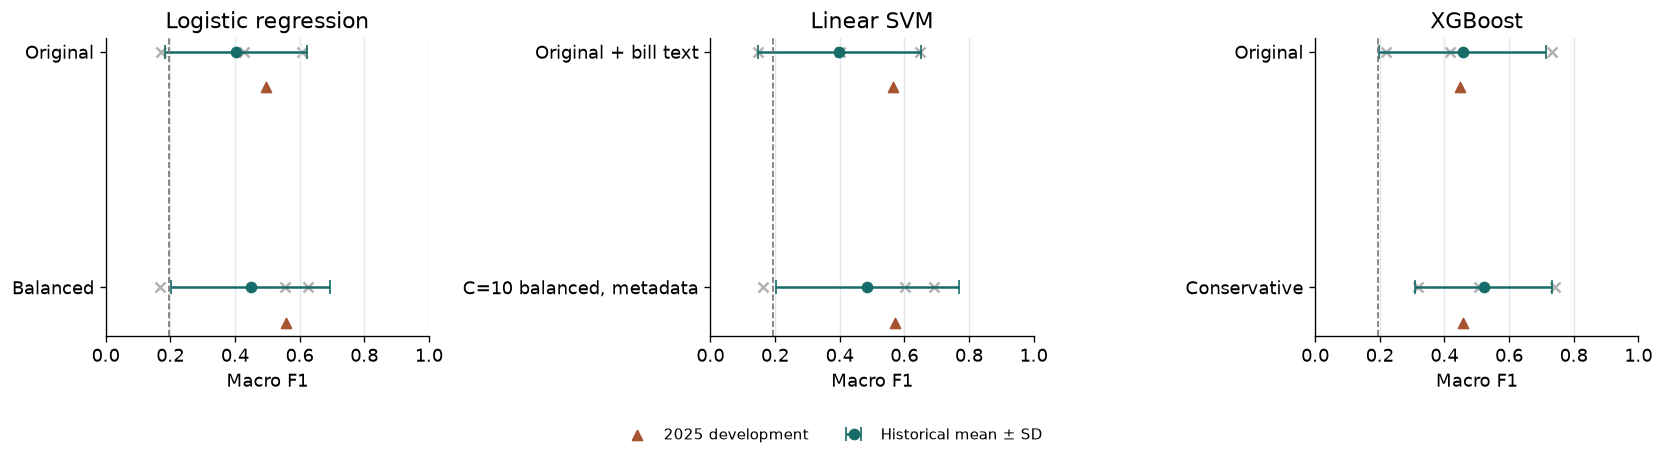

In [7]:
cv = cv_summary.set_index("Config")
dev = validation_summary.set_index("Config")
family_pairs = [
    ("Logistic regression", ["original_lr", "balanced_lr"], ["Original", "Balanced"]),
    ("Linear SVM", ["original_svm", "metadata_svm"], ["Original + bill text", "C=10 balanced, metadata"]),
    ("XGBoost", ["original_xgb", "conservative_xgb"], ["Original", "Conservative"]),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for ax, (family, ids, names) in zip(axes, family_pairs):
    for position, config_id in enumerate(ids):
        yearly = historical_scores.loc[historical_scores["Config"] == config_id, "Macro F1"]
        ax.scatter(yearly, [position] * len(yearly), marker="x", color=GRAY, alpha=0.55)
    ax.errorbar(cv.loc[ids, "Mean macro F1"], range(len(ids)), xerr=cv.loc[ids, "SD macro F1"],
                fmt="o", color=TEAL, capsize=4, label="Historical mean ± SD")
    ax.scatter(dev.loc[ids, "Macro F1"], np.arange(len(ids)) + 0.15, color=RUST,
               marker="^", label="2025 development", zorder=3)
    ax.axvline(cv.loc["majority", "Mean macro F1"], color=GRAY, linestyle="--", linewidth=1)
    ax.set(xlim=(0, 1), xlabel="Macro F1", title=family, yticks=range(len(ids)), yticklabels=names)
    ax.invert_yaxis()
    ax.grid(axis="x", color="#E5E7EB")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, -0.02),
           ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(output_dir / "family_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

### Matched SVM input comparisons

Each panel compares metadata, bill text and combined inputs using the same
model settings. The table shows the macro-F1 difference from metadata alone.
Both panels use the same 0–1 scale and reuse the fits above.

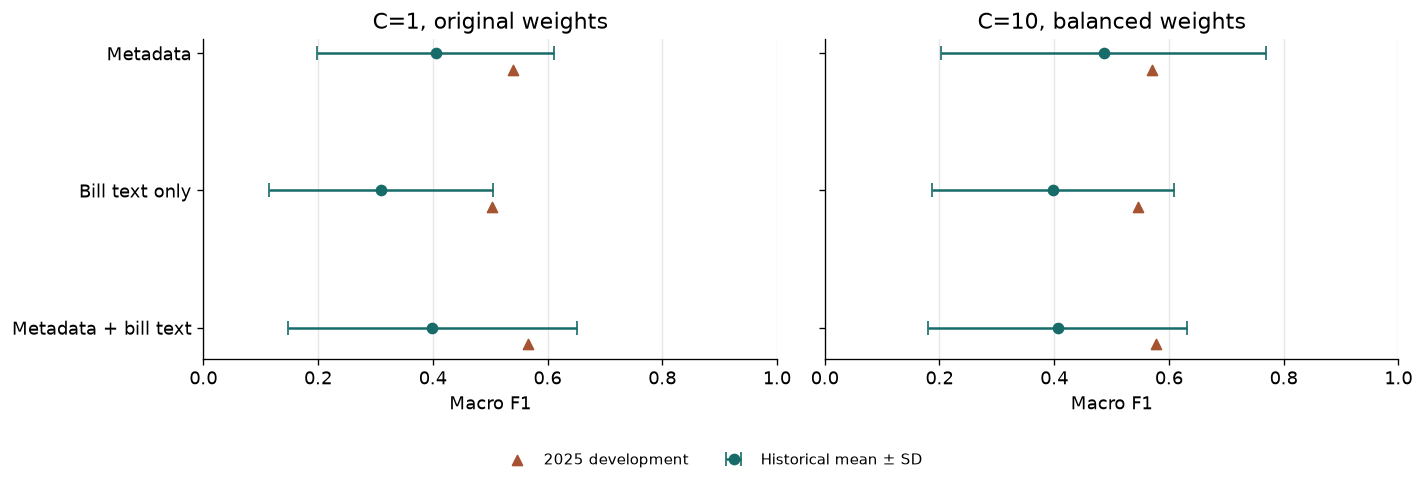

,SVM settings,Input,Historical mean F1,SD,Δ historical F1,2025 F1,Δ 2025 F1
0,"C=1, original weights",Metadata,0.4048,0.2058,0.0000,0.5393,0.0000
1,"C=1, original weights",Bill text only,0.3093,0.1955,-0.0954,0.5036,-0.0357
2,"C=1, original weights",Metadata + bill text,0.3991,0.2518,-0.0057,0.5659,0.0266
3,"C=10, balanced weights",Metadata,0.4860,0.2827,0.0000,0.5701,0.0000
4,"C=10, balanced weights",Bill text only,0.3983,0.2107,-0.0877,0.5463,-0.0237
5,"C=10, balanced weights",Metadata + bill text,0.4060,0.2260,-0.0799,0.5770,0.0069


In [8]:
svm_comparisons = [
    ("C=1, original weights", ["original_svm_metadata", "original_svm_text", "original_svm"]),
    ("C=10, balanced weights", ["metadata_svm", "metadata_svm_text", "metadata_svm_bill_text"]),
]
input_names = ["Metadata", "Bill text only", "Metadata + bill text"]
matched_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, (setting, ids) in zip(axes, svm_comparisons):
    for name, config_id in zip(input_names, ids):
        matched_rows.append({"SVM settings": setting, "Input": name,
                             "Historical mean F1": cv.loc[config_id, "Mean macro F1"],
                             "SD": cv.loc[config_id, "SD macro F1"],
                             "Δ historical F1": cv.loc[config_id, "Mean macro F1"] - cv.loc[ids[0], "Mean macro F1"],
                             "2025 F1": dev.loc[config_id, "Macro F1"],
                             "Δ 2025 F1": dev.loc[config_id, "Macro F1"] - dev.loc[ids[0], "Macro F1"]})
    ax.errorbar(cv.loc[ids, "Mean macro F1"], range(3), xerr=cv.loc[ids, "SD macro F1"],
                fmt="o", color=TEAL, capsize=4, label="Historical mean ± SD")
    ax.scatter(dev.loc[ids, "Macro F1"], np.arange(3) + 0.12, color=RUST,
               marker="^", label="2025 development", zorder=3)
    ax.set(xlim=(0, 1), xlabel="Macro F1", title=setting, yticks=range(3), yticklabels=input_names)
    ax.grid(axis="x", color="#E5E7EB")
axes[0].invert_yaxis()
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, -0.02),
           ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(output_dir / "matched_svm_inputs.png", dpi=180, bbox_inches="tight")
plt.show()
matched_svm = pd.DataFrame(matched_rows)
matched_svm.to_csv(output_dir / "matched_svm_inputs.csv", index=False)
display(matched_svm.round(4))

### Topic features against matched candidates

Each topic variant keeps its classifier settings and base inputs fixed. Deltas
are absolute F1 differences from that base, not percentage changes. Topics
also introduce summary information, so a gain over the base does not by itself
show that topic compression helps. The second table compares metadata-SVM
topics directly with its matched raw summary control. LDA's count input also
differs from that control's TF-IDF representation.

In [9]:
topic_rows = []
for base_id in ["balanced_lr", "metadata_svm", "conservative_xgb"]:
    for suffix, name in [("nmf", "NMF8"), ("lda", "LDA8")]:
        config_id = f"{base_id}_{suffix}"
        topic_rows.append({"Base": base_id, "Added topics": name,
                           "Historical mean F1": cv.loc[config_id, "Mean macro F1"],
                           "SD": cv.loc[config_id, "SD macro F1"],
                           "Pooled OOF F1": cv.loc[config_id, "Pooled OOF macro F1"],
                           "Δ historical F1": cv.loc[config_id, "Mean macro F1"] - cv.loc[base_id, "Mean macro F1"],
                           "2025 F1": dev.loc[config_id, "Macro F1"],
                           "Δ 2025 F1": dev.loc[config_id, "Macro F1"] - dev.loc[base_id, "Macro F1"],
                           "2025 Passed recall": dev.loc[config_id, "Passed recall"]})
topic_comparison = pd.DataFrame(topic_rows)
control_ids = ["metadata_svm_summary", "metadata_svm_nmf", "metadata_svm_lda"]
summary_control = pd.DataFrame({
    "Summary representation": ["Raw TF-IDF", "NMF8", "LDA8"],
    "Historical mean F1": cv.loc[control_ids, "Mean macro F1"].to_numpy(),
    "2025 F1": dev.loc[control_ids, "Macro F1"].to_numpy(),
})
summary_control["Δ historical vs raw"] = summary_control["Historical mean F1"] - summary_control.loc[0, "Historical mean F1"]
summary_control["Δ 2025 vs raw"] = summary_control["2025 F1"] - summary_control.loc[0, "2025 F1"]
topic_comparison.to_csv(output_dir / "topic_candidate_comparison.csv", index=False)
summary_control.to_csv(output_dir / "summary_representation_control.csv", index=False)
display(topic_comparison.round(4), summary_control.round(4))

,Base,Added topics,Historical mean F1,SD,Pooled OOF F1,Δ historical F1,2025 F1,Δ 2025 F1,2025 Passed recall
0,balanced_lr,NMF8,0.4279,0.2512,0.5421,-0.0209,0.5581,-0.0012,0.3459
1,balanced_lr,LDA8,0.4424,0.2277,0.5422,-0.0065,0.5580,-0.0013,0.3351
2,metadata_svm,NMF8,0.4050,0.2007,0.5509,-0.0809,0.5744,0.0043,0.3405
3,metadata_svm,LDA8,0.4822,0.2313,0.5739,-0.0037,0.5487,-0.0214,0.2757
4,conservative_xgb,NMF8,0.5385,0.2225,0.7056,0.0169,0.4556,-0.0030,0.0973
5,conservative_xgb,LDA8,0.5227,0.2347,0.6941,0.0011,0.4466,-0.0120,0.0865


,Summary representation,Historical mean F1,2025 F1,Δ historical vs raw,Δ 2025 vs raw
0,Raw TF-IDF,0.3858,0.5372,0.0000,0.0000
1,NMF8,0.4050,0.5744,0.0192,0.0371
2,LDA8,0.4822,0.5487,0.0964,0.0115


The tables above compare development results only. Rankings, minority-class
recovery, similar bill text and later-stage wording all affect how we interpret
them. Results are saved in `outputs/model_evaluation/`; this notebook does not
score the 2026 cohort.

## Related-text sensitivity

Bills in different years can share substantial wording. This check removes
earlier training texts with cosine similarity of at least 0.95 to **any**
validation text, then refits five fixed configurations. Every configuration
still scores the same complete validation cohort. The separate screening
vocabulary learns only from the original training text; each classifier and
its preprocessing learn afresh from the remaining training records.

The 0.95 threshold is fixed for this development check, not tuned against
outcomes. Validation text determines which training rows are removed; validation
labels do not. Score changes combine removing similar examples with reducing
and changing the training population. They do not measure leakage inflation
or establish verified bill families. Boilerplate and less-similar relationships
can remain. Chronological splitting remains the main comparison.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

overlap_ids = ['original_svm', 'metadata_svm', 'metadata_svm_bill_text', 'balanced_lr', 'conservative_xgb_nmf']
overlap_rows, overlap_predictions, screening_rows, match_rows = [], [], [], []
for year, train, holdout in folds + [(2025, training, validation)]:
    screen = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=10000)
    train_vectors = screen.fit_transform(train['Bill_Text_clean'])
    similarities = cosine_similarity(screen.transform(holdout['Bill_Text_clean']), train_vectors)
    close_training = similarities.max(axis=0) >= 0.95
    reduced = train.loc[~close_training].copy()
    if not set(LABELS).issubset(reduced[TARGET]):
        raise ValueError(f'{year}: overlap removal leaves a training class empty.')
    screening_rows.append({
        'Year': year, 'Training before': len(train), 'Training after': len(reduced),
        'Removed': int(close_training.sum()), 'Validation rows': len(holdout),
        'Validation with close text': int((similarities.max(axis=1) >= 0.95).sum()),
        **{f'{label} remaining': int(reduced[TARGET].eq(label).sum()) for label in LABELS},
    })
    nearest = similarities.argmax(axis=1)
    match_rows.extend({'Year': year, 'source_row': row,
                      'Closest training source_row': train.iloc[match].source_row,
                      'Cosine similarity': value}
                     for row, match, value in zip(holdout.source_row, nearest, similarities.max(axis=1)))
    for config in [c for c in configs if c['id'] in overlap_ids]:
        _, score, row_predictions = run_configuration(config, reduced, holdout, year)
        overlap_rows.append(score)
        overlap_predictions.append(row_predictions)
    print(f'{year}: removed {close_training.sum()} of {len(train)} training records.')

screening = pd.DataFrame(screening_rows)
overlap_scores = pd.DataFrame(overlap_rows)
paired_overlap = overlap_scores[['Config', 'Year', 'Macro F1']].merge(
    fold_scores[['Config', 'Year', 'Macro F1']], on=['Config', 'Year'],
    suffixes=(' screened training', ' original training'), validate='one_to_one')
paired_overlap['Change'] = paired_overlap['Macro F1 screened training'] - paired_overlap['Macro F1 original training']
screening.to_csv(output_dir / 'overlap_training_counts.csv', index=False)
pd.DataFrame(match_rows).to_csv(output_dir / 'overlap_nearest_matches.csv', index=False)
overlap_scores.to_csv(output_dir / 'overlap_scores.csv', index=False)
pd.concat(overlap_predictions, ignore_index=True).to_csv(output_dir / 'overlap_predictions.csv', index=False)
paired_overlap.to_csv(output_dir / 'overlap_paired_scores.csv', index=False)
display(screening)
display(paired_overlap.round(4))

2022: removed 6 of 129 training records.


2023: removed 11 of 162 training records.


2024: removed 18 of 252 training records.


2025: removed 118 of 722 training records.


,Year,Training before,Training after,Removed,Validation rows,Validation with close text,Failed remaining,Passed remaining,Pending remaining
0,2022,129,123,6,33,6,83,24,16
1,2023,162,151,11,90,9,106,27,18
2,2024,252,234,18,470,18,128,33,73
3,2025,722,604,118,1016,119,293,91,220


,Config,Year,Macro F1 screened training,Macro F1 original training,Change
0,balanced_lr,2022,0.5535,0.5535,0.0000
1,original_svm,2022,0.3573,0.4015,-0.0442
2,metadata_svm,2022,0.6659,0.6928,-0.0268
3,conservative_xgb_nmf,2022,0.5062,0.5062,0.0000
4,metadata_svm_bill_text,2022,0.4101,0.3603,0.0498
5,balanced_lr,2023,0.1606,0.1676,-0.0070
6,original_svm,2023,0.1535,0.1461,0.0074
7,metadata_svm,2023,0.2030,0.1638,0.0393
8,conservative_xgb_nmf,2023,0.3329,0.3338,-0.0009
9,metadata_svm_bill_text,2023,0.1942,0.2063,-0.0122


## Regularization sensitivity

For the balanced metadata and metadata-plus-bill-text SVMs, vary only `C`
over `0.1`, `1` and `10`. Smaller `C` means stronger regularization.
Class weights, labels, features, preprocessing and the four evaluation cohorts
remain fixed. The existing `C=10` scores are reused; the other settings fit
fresh training-only pipelines. The table reports historical mean and sample
SD separately from 2025 development scores. These are development comparisons;
Notebook 07 reports the separate 2026 final evaluation.

In [11]:
regularization_rows = []
for base_id in ['metadata_svm', 'metadata_svm_bill_text']:
    base = next(c for c in configs if c['id'] == base_id)
    for c_value in [0.1, 1, 10]:
        if c_value == 10:
            rows = fold_scores.loc[fold_scores.Config.eq(base_id)].to_dict('records')
        else:
            config = {**base, 'id': f'{base_id}_C{c_value:g}',
                      'model_params': {**base['model_params'], 'C': c_value}}
            rows = []
            for year, train, holdout in folds + [(2025, training, validation)]:
                _, score, _ = run_configuration(config, train, holdout, year)
                rows.append(score)
        regularization_rows.extend({**row, 'Base config': base_id, 'C': c_value} for row in rows)
regularization_scores = pd.DataFrame(regularization_rows)
regularization_keys = ['Base config', 'C']
regularization_summary = regularization_scores.loc[regularization_scores.Year.lt(2025)].groupby(
    regularization_keys, sort=False).agg(
        **{'Historical mean F1': ('Macro F1', 'mean'), 'Historical SD': ('Macro F1', 'std')}
    ).join(regularization_scores.loc[regularization_scores.Year.eq(2025)].set_index(
        regularization_keys)[['Macro F1', 'Passed precision', 'Passed recall']].rename(columns={
            'Macro F1': '2025 macro F1', 'Passed precision': '2025 Passed precision',
            'Passed recall': '2025 Passed recall'}))
regularization_scores.to_csv(output_dir / 'svm_regularization_scores.csv', index=False)
regularization_summary.to_csv(output_dir / 'svm_regularization_summary.csv')
display(regularization_summary.round(4))

Historical mean F1  Historical SD  2025 macro F1  \
Base config            C                                                        
metadata_svm           0.1               0.4340         0.2383         0.5146   
                       1.0               0.4760         0.2778         0.5579   
                       10.0              0.4860         0.2827         0.5701   
metadata_svm_bill_text 0.1               0.4170         0.2469         0.5182   
                       1.0               0.3821         0.2583         0.5767   
                       10.0              0.4060         0.2260         0.5770   

                             2025 Passed precision  2025 Passed recall  
Base config            C                                                
metadata_svm           0.1                  0.3452              0.1568  
                       1.0                  0.3953              0.2757  
                       10.0                 0.4106              0.3351  
metadata_svm_bill_text 0.1                  0.3704              0.1622  
                       1.0                  0.4649              0.2865  
                       10.0                 0.4914              0.3081

## Metadata contribution and SVM interpretation

The balanced metadata and metadata-plus-bill-text SVMs both use `C=10`.
Each removal below holds class weights, records and folds fixed; the combined
candidate also retains the same bill-text branch. The sponsor group contains
all eight derived sponsor fields. These development checks describe each
candidate; they do not select a reduced feature set or a final model.

The three SVM coefficient tables use their own fitted encodings and scales.
A large coefficient is an association within that model, not a causal effect
or a comparable importance measure across different encodings. In the text
models, later-stage wording also limits interpretation as an early prediction.

In [12]:
diagnostic_ids = ['original_svm', 'metadata_svm', 'metadata_svm_bill_text']
balanced_svm_ids = ['metadata_svm', 'metadata_svm_bill_text']
removed_groups = {
    'Without sponsors': ['D_Count', 'R_Count', 'Other_Count', 'Unknown_Count',
                         'Total_Sponsors', 'Bipartisan_Support',
                         'Democrat_Sponsor_Ratio', 'Republican_Sponsor_Ratio'],
    'Without state': ['Jurisdiction'],
    'Without political control': ['State_Political_Control'],
    'Without measure type': ['measure_code'],
}
ablations, ablation_predictions = [], []
for base_id in balanced_svm_ids:
    base = next(c for c in configs if c['id'] == base_id)
    baseline = fold_scores.loc[fold_scores.Config.eq(base_id)].copy()
    ablations.append(baseline.assign(**{'Base config': base_id, 'Variant': 'All metadata'}))
    for name, excluded in removed_groups.items():
        config = {**base, 'id': name if base_id == 'metadata_svm' else f'{base_id}: {name}',
                  'feature_groups': {group: [col for col in columns if col not in excluded]
                                     for group, columns in FEATURE_GROUPS.items()}}
        rows = []
        for year, train, holdout in folds + [(2025, training, validation)]:
            _, score, row_predictions = run_configuration(config, train, holdout, year)
            rows.append({**score, 'Base config': base_id, 'Variant': name})
            ablation_predictions.append(row_predictions.assign(**{'Base config': base_id, 'Variant': name}))
        ablations.append(pd.DataFrame(rows))
ablation_scores = pd.concat(ablations, ignore_index=True)
ablation_keys = ['Base config', 'Variant']
ablation_summary = ablation_scores.loc[ablation_scores.Year.lt(2025)].groupby(ablation_keys, sort=False).agg(
    CV_mean=('Macro F1', 'mean'), CV_SD=('Macro F1', 'std')).join(
        ablation_scores.loc[ablation_scores.Year.eq(2025)].set_index(ablation_keys)[['Macro F1', 'Passed recall']])
ablation_scores.to_csv(output_dir / 'metadata_ablation_scores.csv', index=False)
pd.concat(ablation_predictions, ignore_index=True).to_csv(output_dir / 'metadata_ablation_predictions.csv', index=False)
ablation_summary.to_csv(output_dir / 'metadata_ablation_summary.csv')
display(ablation_summary.rename(columns={'Macro F1': '2025 macro F1', 'Passed recall': '2025 Passed recall'}).round(4))

coefficient_tables = []
for config_id in diagnostic_ids:
    pipeline = validation_runs[config_id]['pipeline']
    feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
    model = pipeline.named_steps['classifier']
    for label, coefficients in zip(model.classes_, model.coef_):
        coefficient_tables.append(pd.DataFrame({'Config': config_id, 'Class': label,
            'Feature': feature_names, 'Coefficient': coefficients}))
coefficients = pd.concat(coefficient_tables, ignore_index=True)
coefficients.to_csv(output_dir / 'svm_coefficients.csv', index=False)
leading = coefficients.sort_values('Coefficient', ascending=False).groupby(['Config', 'Class'], sort=False).head(8)
display(leading.loc[leading.Class.eq('Passed')].round(3))

CV_mean   CV_SD  \
Base config            Variant                                      
metadata_svm           All metadata                0.4860  0.2827   
                       Without sponsors            0.4490  0.3070   
                       Without state               0.4472  0.1098   
                       Without political control   0.4927  0.2710   
                       Without measure type        0.4900  0.2831   
metadata_svm_bill_text All metadata                0.4060  0.2260   
                       Without sponsors            0.4681  0.2688   
                       Without state               0.3942  0.1830   
                       Without political control   0.3721  0.2224   
                       Without measure type        0.3835  0.2566   

                                                  2025 macro F1  \
Base config            Variant                                    
metadata_svm           All metadata                      0.5701   
                       Without sponsors                  0.5380   
                       Without state                     0.4812   
                       Without political control         0.5510   
                       Without measure type              0.5170   
metadata_svm_bill_text All metadata                      0.5770   
                       Without sponsors                  0.5858   
                       Without state                     0.5281   
                       Without political control         0.5782   
                       Without measure type              0.5544   

                                                  2025 Passed recall  
Base config            Variant                                        
metadata_svm           All metadata                           0.3351  
                       Without sponsors                       0.2865  
                       Without state                          0.1892  
                       Without political control              0.2757  
                       Without measure type                   0.1676  
metadata_svm_bill_text All metadata                           0.3081  
                       Without sponsors                       0.3459  
                       Without state                          0.2270  
                       Without political control              0.3243  
                       Without measure type                   0.2486

,Config,Class,Feature,Coefficient
25455,metadata_svm_bill_text,Passed,text__version enacted,5.362
21164,metadata_svm_bill_text,Passed,text__approved,2.510
15326,metadata_svm,Passed,categorical__measure_code_HR,2.347
9981,original_svm,Passed,text__version enacted,2.294
21165,metadata_svm_bill_text,Passed,text__approved by,2.151
22380,metadata_svm_bill_text,Passed,text__final,1.989
23810,metadata_svm_bill_text,Passed,text__passed,1.966
15319,metadata_svm,Passed,categorical__measure_code_AR,1.898
22186,metadata_svm_bill_text,Passed,text__enacted,1.878
22212,metadata_svm_bill_text,Passed,text__enrolled,1.739


## Precision, recall and failed predictions

Passed recall counts how many recorded Passed bills the classifier recovers.
Passed precision counts how many predicted Passed bills actually have that
source label. The original SVM and both balanced candidates use the same
2025 records below. No model is treated as a final winner.

For each balanced candidate, three errors represent different
recorded-to-predicted pairs: Failed-to-Passed, Passed-to-Failed and
Pending-to-Failed. The first source row for each pair makes selection
reproducible. The examples are illustrative, not representative error rates.
Their source fields do not prove why the model made a mistake. These examples
use the published labels, without applying later source observations.

,Config,Features,Passed recovered,False Passed,Passed precision,Passed recall
0,original_svm,5079,44,47,0.4835,0.2378
1,metadata_svm,79,62,89,0.4106,0.3351
2,metadata_svm_bill_text,5079,57,59,0.4914,0.3081


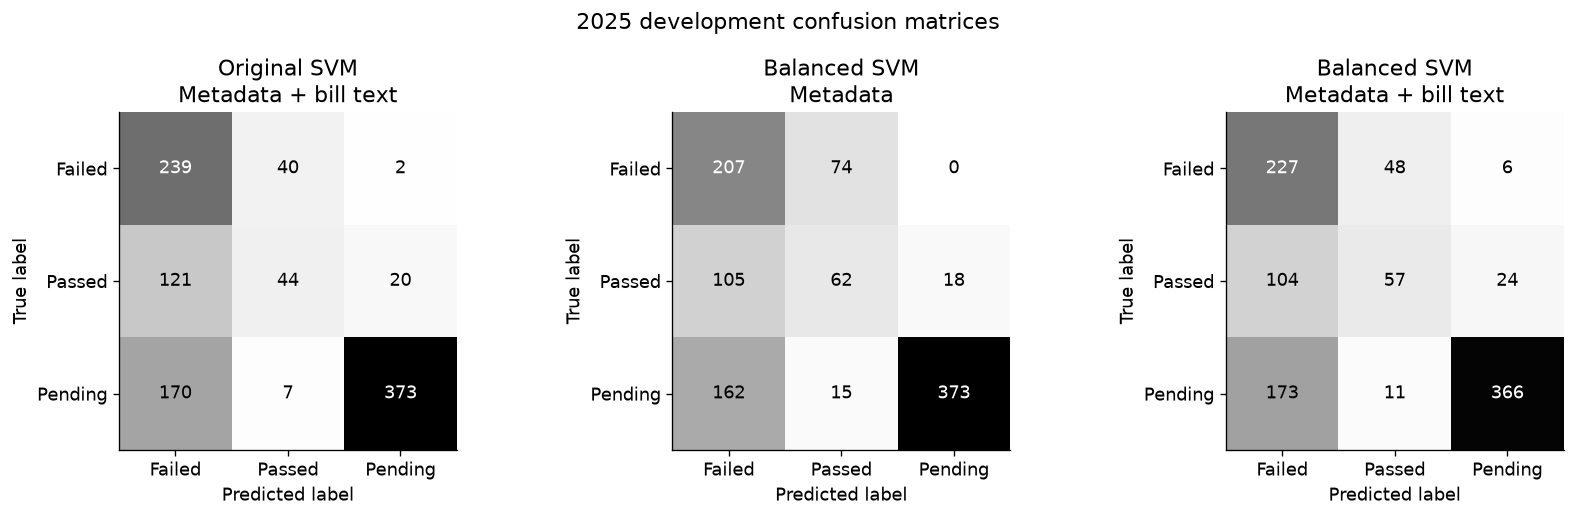

Balanced SVM + metadata


,source_row,Jurisdiction,Bill_Number,Bill_Title,Recorded,Predicted,Original SVM
0,1,Alabama,H 208,State Government,Failed,Passed,Failed
10,11,Arizona,H 2175,Claims and Prior Authorization,Passed,Failed,Failed
7,8,Alaska,HCR 3,Artificial Intelligence Legislative Task Force,Pending,Failed,Failed


Balanced SVM: metadata + bill text


,source_row,Jurisdiction,Bill_Number,Bill_Title,Recorded,Predicted,Original SVM
5,6,Alabama,HR 244,Commending Ignite,Failed,Passed,Passed
12,13,Arizona,H 2678,Indistinguishable and Visual Depiction and Def...,Passed,Failed,Failed
7,8,Alaska,HCR 3,Artificial Intelligence Legislative Task Force,Pending,Failed,Failed


In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

tradeoff = []
for config_id in diagnostic_ids:
    run = validation_runs[config_id]
    actual, predicted = np.asarray(run['y_val']), np.asarray(run['val_predictions'])
    correct = int(((actual == 'Passed') & (predicted == 'Passed')).sum())
    incorrect = int(((actual != 'Passed') & (predicted == 'Passed')).sum())
    pipeline = run['pipeline']
    tradeoff.append({'Config': config_id,
        'Features': len(pipeline.named_steps['preprocessor'].get_feature_names_out()),
        'Passed recovered': correct, 'False Passed': incorrect,
        'Passed precision': correct / (correct + incorrect) if correct + incorrect else 0,
        'Passed recall': correct / int((actual == 'Passed').sum())})
tradeoff = pd.DataFrame(tradeoff)
tradeoff.to_csv(output_dir / 'svm_tradeoff.csv', index=False)
display(tradeoff.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
maximum = max(confusion_matrix(validation[TARGET], validation_runs[key]['val_predictions'], labels=LABELS).max()
              for key in diagnostic_ids)
titles = ['Original SVM\nMetadata + bill text', 'Balanced SVM\nMetadata',
          'Balanced SVM\nMetadata + bill text']
for axis, config_id, title in zip(axes, diagnostic_ids, titles):
    run = validation_runs[config_id]
    ConfusionMatrixDisplay.from_predictions(run['y_val'], run['val_predictions'],
        labels=LABELS, ax=axis, colorbar=False, cmap='Greys', im_kw={'vmin': 0, 'vmax': maximum})
    axis.set_title(title)
fig.suptitle('2025 development confusion matrices')
fig.tight_layout()
fig.savefig(output_dir / 'svm_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

case_columns = ['source_row', 'Jurisdiction', 'Bill_Number', 'Bill_Title', 'measure_code',
                'D_Count', 'R_Count', 'Bipartisan_Support', 'Bill_Status', 'Bill_URL']
error_pairs = [('Failed', 'Passed'), ('Passed', 'Failed'), ('Pending', 'Failed')]
for config_id in balanced_svm_ids:
    cases = validation[case_columns].copy()
    cases['Recorded'] = validation[TARGET].to_numpy()
    cases['Predicted'] = validation_runs[config_id]['val_predictions']
    cases['Original SVM'] = validation_runs['original_svm']['val_predictions']
    example_frames = []
    for recorded, predicted in error_pairs:
        matches = cases.loc[cases['Recorded'].eq(recorded) & cases['Predicted'].eq(predicted)]
        example_frames.append(matches.sort_values('source_row').head(1))
    examples = pd.concat(example_frames)
    examples.to_csv(output_dir / f'{config_id}_failure_cases.csv', index=False)
    print(next(c['label'] for c in configs if c['id'] == config_id))
    display(examples[['source_row', 'Jurisdiction', 'Bill_Number', 'Bill_Title',
                      'Recorded', 'Predicted', 'Original SVM']])

## Findings and limits

The matched-input comparisons distinguish text contribution from changes in
regularization or class weights. The topic comparisons keep each base model's
settings fixed; the raw-summary control separates adding summary information
from compressing that information into topics. Topic quality in the descriptive
analysis remains a separate question from outcome-classification performance.

Balanced metadata plus bill text gives nearly equal 2025 macro F1 at `C=1`
and `C=10` (0.5767 and 0.5770); metadata alone has the higher `C=10`
historical mean (0.4860 versus 0.4060). Removing sponsors raises combined-input
2025 macro F1 from 0.5770 to 0.5858 but lowers metadata-only F1 from 0.5701
to 0.5380, so these development tradeoffs do not establish final inputs.

Historical yearly samples are small and differ in class balance. Equal-year
means and pooled out-of-fold F1 answer different aggregation questions. Their
spread, repeated development use of 2025, later-stage source information and
unverified bill-family relationships limit generalization claims. The overlap
check is a sensitivity analysis, not a correction for dependence. No 2026
records are fitted or scored here.